<a href="https://colab.research.google.com/github/SanjaGrujicic/klasifikacija-sisara/blob/main/KLasifikacija_slika_sisara.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Klasifikacija slika sisara primenom dubokog učenja

## Opis projekta

Tema ovog projekta je klasifikacija slika sisara pomoću metoda mašinskog i dubokog učenja. Cilj projekta je da se na osnovu ulazne slike automatski odredi kojoj klasi, odnosno kojoj vrsti sisara, slika pripada.

U radu je korišćen skup podataka koji sadrži slike različitih sisara organizovane po klasama. Dataset obuhvata 45 klasa i ukupno 13.751 sliku. Svaka klasa predstavlja jednu vrstu sisara, kao što su `african_elephant`, `alpaca`, `arctic_fox`, `brown_bear`, `zebra` i druge.

Projekat obuhvata analizu skupa podataka, prikaz raspodele slika po klasama, pregled primera slika, pripremu i normalizaciju podataka, podelu na trening, validacioni i test skup, kao i treniranje i evaluaciju modela za klasifikaciju slika.

Kao početni model korišćena je jednostavna konvoluciona neuronska mreža, dok je kao napredniji pristup korišćen MobileNetV2 model zasnovan na transfer learning-u. Rezultati modela porede se na osnovu tačnosti i funkcije greške, sa ciljem da se pokaže prednost korišćenja prethodno treniranih modela u problemima klasifikacije slika.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

ZIP_PATH = "/content/drive/MyDrive/PPPO_projekat/Mammlas_Image_Classification_Dataset.zip"

print("Da li ZIP postoji?", os.path.exists(ZIP_PATH))

if os.path.exists(ZIP_PATH):
    print("Veličina fajla u MB:", round(os.path.getsize(ZIP_PATH) / (1024 * 1024), 2))

Da li ZIP postoji? True
Veličina fajla u MB: 184.55


In [ ]:
import zipfile
from pathlib import Path

DATA_DIR = Path("/content/mammals_dataset")

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(DATA_DIR)

print("Dataset je raspakovan u:", DATA_DIR)

Dataset je raspakovan u: /content/mammals_dataset


In [ ]:
from pathlib import Path

DATA_ROOT = Path("/content/mammals_dataset/mammals")

classes = sorted([folder.name for folder in DATA_ROOT.iterdir() if folder.is_dir()])

print("Broj klasa:", len(classes))
print("Prvih 10 klasa:")
print(classes[:10])

Broj klasa: 45
Prvih 10 klasa:
['african_elephant', 'alpaca', 'american_bison', 'anteater', 'arctic_fox', 'armadillo', 'baboon', 'badger', 'blue_whale', 'brown_bear']


In [ ]:
from pathlib import Path
import zipfile
import os

ZIP_PATH = "/content/drive/MyDrive/PPPO_projekat/Mammlas_Image_Classification_Dataset.zip"

DATA_DIR = Path("/content/mammals_dataset")
DATA_ROOT = DATA_DIR / "mammals"

if not DATA_ROOT.exists():
    print("Dataset nije raspakovan, raspakujem sada...")
    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(DATA_DIR)

print("DATA_ROOT:", DATA_ROOT)
print("Da li folder postoji?", DATA_ROOT.exists())

classes = sorted([folder.name for folder in DATA_ROOT.iterdir() if folder.is_dir()])
print("Broj klasa:", len(classes))
print("Prvih 10 klasa:", classes[:10])

DATA_ROOT: /content/mammals_dataset/mammals
Da li folder postoji? True
Broj klasa: 45
Prvih 10 klasa: ['african_elephant', 'alpaca', 'american_bison', 'anteater', 'arctic_fox', 'armadillo', 'baboon', 'badger', 'blue_whale', 'brown_bear']


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Analiza skupa podataka

U ovom delu analiziran je skup slika sisara. Dataset je organizovan tako da svaka klasa predstavlja jednu vrstu sisara, a slike se nalaze u posebnim folderima prema nazivu klase.

In [ ]:
import pandas as pd

class_counts = []

for class_folder in sorted(DATA_ROOT.iterdir()):
    if class_folder.is_dir():
        images = [
            file for file in class_folder.iterdir()
            if file.suffix.lower() in [".jpg", ".jpeg", ".png"]
        ]

        class_counts.append({
            "class_name": class_folder.name,
            "image_count": len(images)
        })

df_counts = pd.DataFrame(class_counts)

print("Ukupan broj slika:", df_counts["image_count"].sum())
print("Broj klasa:", len(df_counts))
print("Najmanja klasa:", df_counts["image_count"].min())
print("Najveća klasa:", df_counts["image_count"].max())

df_counts

Ukupan broj slika: 13751
Broj klasa: 45
Najmanja klasa: 215
Najveća klasa: 356


,class_name,image_count
0,african_elephant,347
1,alpaca,333
2,american_bison,343
3,anteater,299
4,arctic_fox,315
5,armadillo,331
6,baboon,330
7,badger,310
8,blue_whale,243
9,brown_bear,300


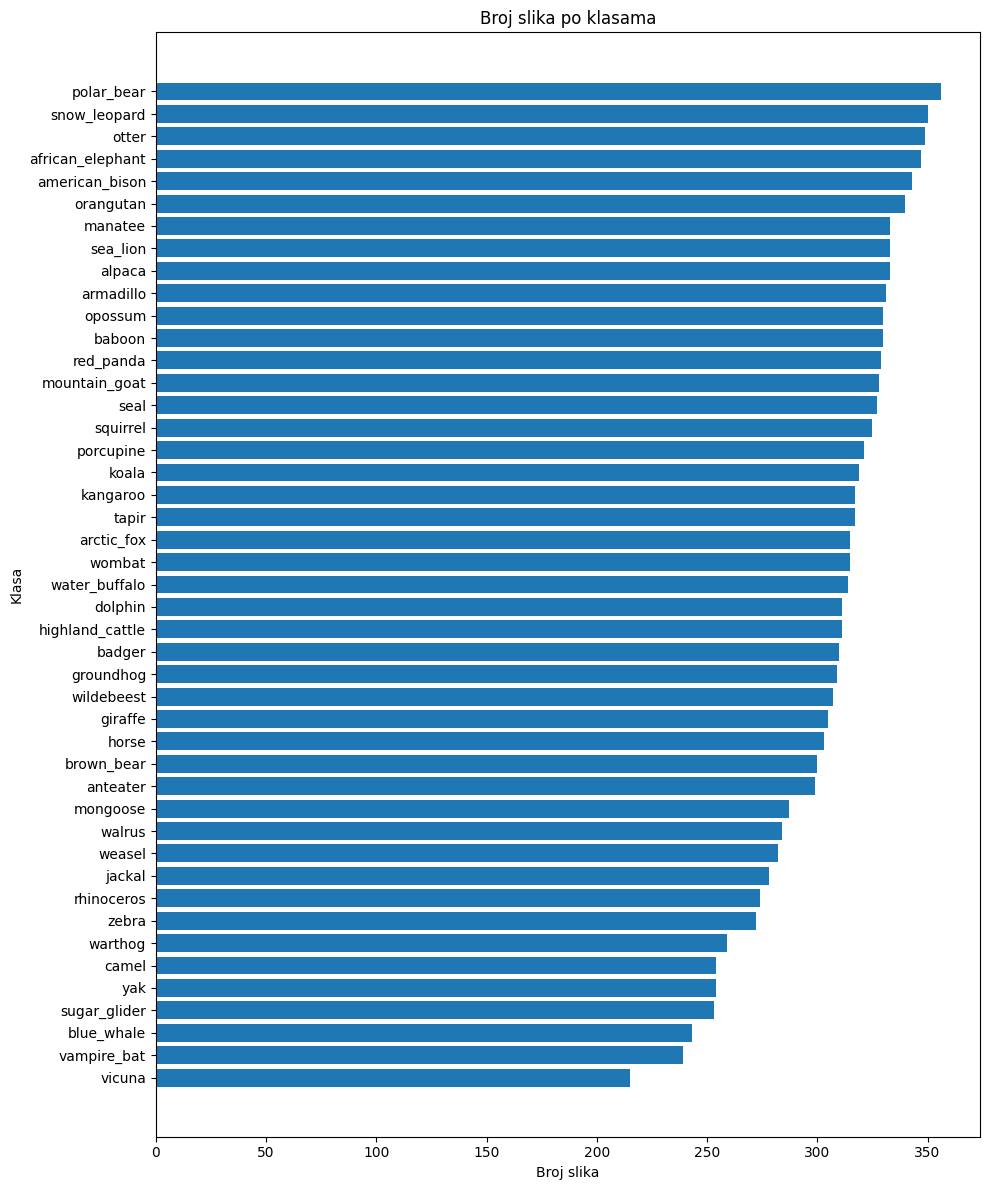

In [ ]:
import matplotlib.pyplot as plt

df_sorted = df_counts.sort_values("image_count", ascending=True)

plt.figure(figsize=(10, 12))
plt.barh(df_sorted["class_name"], df_sorted["image_count"])
plt.xlabel("Broj slika")
plt.ylabel("Klasa")
plt.title("Broj slika po klasama")
plt.tight_layout()
plt.show()

Na grafikonu je prikazan broj slika po klasama. Dataset sadrži 45 klasa sisara, pri čemu broj slika po klasi varira približno od 215 do 356. Najviše slika ima klasa polar_bear, dok najmanje ima klasa vicuna. Iako skup podataka nije potpuno balansiran, razlike između većine klasa nisu ekstremne, pa se dataset može koristiti za treniranje modela za višeklasnu klasifikaciju slika.

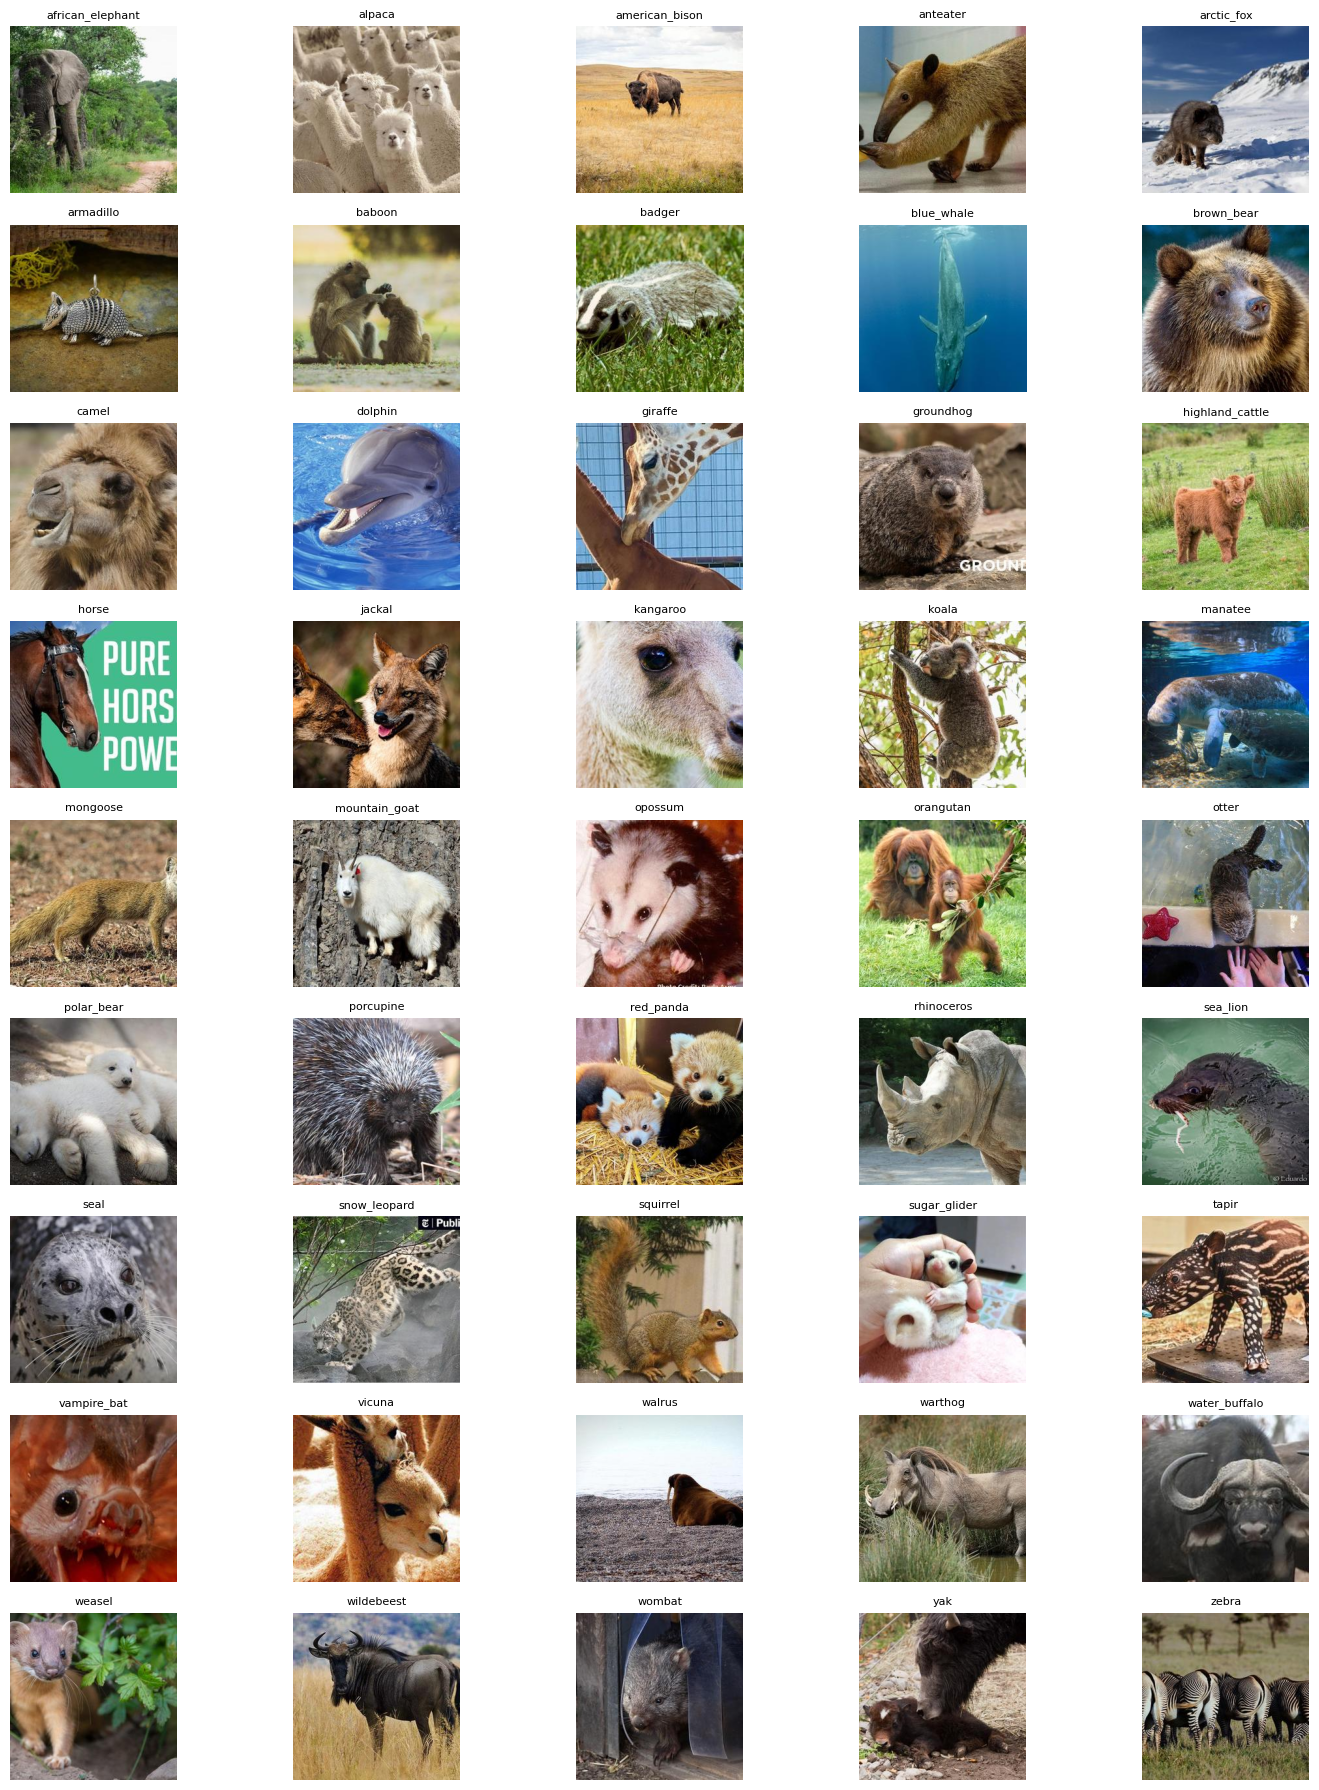

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import random

class_names = sorted([folder.name for folder in DATA_ROOT.iterdir() if folder.is_dir()])

plt.figure(figsize=(15, 18))

for i, class_name in enumerate(class_names):
    class_path = DATA_ROOT / class_name

    image_paths = [
        file for file in class_path.iterdir()
        if file.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]

    random_image_path = random.choice(image_paths)
    image = Image.open(random_image_path).convert("RGB")

    plt.subplot(9, 5, i + 1)
    plt.imshow(image)
    plt.title(class_name, fontsize=8)
    plt.axis("off")

plt.tight_layout()
plt.show()

## Analiza dimenzija slika

U ovom koraku proveravaju se dimenzije slika u dataset-u. Pošto slike mogu imati različite širine i visine, pre treniranja modela potrebno ih je resize-ovati na jedinstvenu dimenziju.

In [ ]:
from PIL import Image
import pandas as pd

image_info = []

for class_folder in sorted(DATA_ROOT.iterdir()):
    if class_folder.is_dir():
        for image_path in class_folder.iterdir():
            if image_path.suffix.lower() in [".jpg", ".jpeg", ".png"]:
                try:
                    with Image.open(image_path) as img:
                        width, height = img.size

                    image_info.append({
                        "class_name": class_folder.name,
                        "file_name": image_path.name,
                        "width": width,
                        "height": height
                    })
                except Exception as e:
                    print("Problem sa slikom:", image_path, e)

df_images = pd.DataFrame(image_info)

print("Ukupan broj analiziranih slika:", len(df_images))
print("Najmanja širina:", df_images["width"].min())
print("Najveća širina:", df_images["width"].max())
print("Najmanja visina:", df_images["height"].min())
print("Najveća visina:", df_images["height"].max())

df_images.head()

Ukupan broj analiziranih slika: 13751
Najmanja širina: 256
Najveća širina: 256
Najmanja visina: 256
Najveća visina: 256


,class_name,file_name,width,height
0,african_elephant,african_elephant-0150.jpg,256,256
1,african_elephant,african_elephant-0137.jpg,256,256
2,african_elephant,african_elephant-0294.jpg,256,256
3,african_elephant,african_elephant-0001.jpg,256,256
4,african_elephant,african_elephant-0270.jpg,256,256


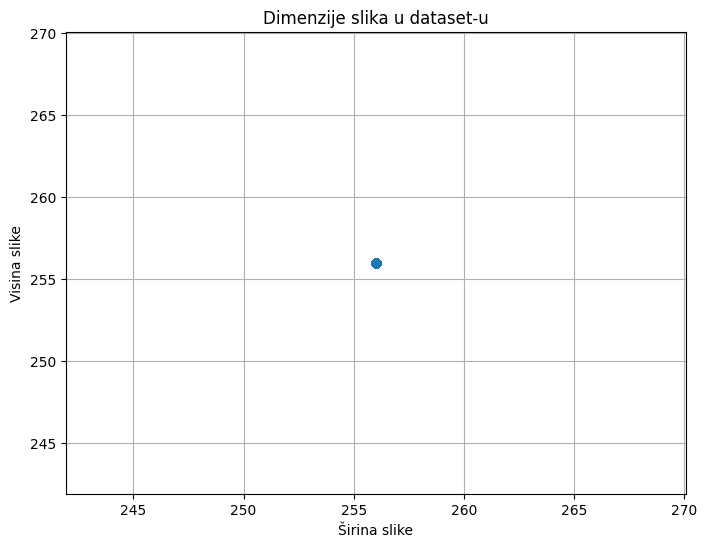

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(df_images["width"], df_images["height"], alpha=0.3)
plt.xlabel("Širina slike")
plt.ylabel("Visina slike")
plt.title("Dimenzije slika u dataset-u")
plt.grid(True)
plt.show()

## Podela podataka na trening, validacioni i test skup

Dataset je podeljen na trening, validacioni i test skup. Trening skup se koristi za učenje modela, validacioni skup za praćenje performansi tokom treniranja, dok se test skup koristi za konačnu procenu modela na slikama koje model nije video tokom učenja.

In [ ]:
from sklearn.model_selection import train_test_split
import pandas as pd

image_paths = []
labels = []
class_names = sorted([folder.name for folder in DATA_ROOT.iterdir() if folder.is_dir()])

for label, class_name in enumerate(class_names):
    class_folder = DATA_ROOT / class_name

    for image_path in class_folder.iterdir():
        if image_path.suffix.lower() in [".jpg", ".jpeg", ".png"]:
            image_paths.append(str(image_path))
            labels.append(label)

df = pd.DataFrame({
    "image_path": image_paths,
    "label": labels
})

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

print("Broj slika za trening:", len(train_df))
print("Broj slika za validaciju:", len(val_df))
print("Broj slika za test:", len(test_df))
print("Ukupno:", len(train_df) + len(val_df) + len(test_df))

Broj slika za trening: 9625
Broj slika za validaciju: 2063
Broj slika za test: 2063
Ukupno: 13751


## Priprema podataka za model

Slike se učitavaju iz fajlova, resize-uju na dimenziju 224x224 piksela i normalizuju tako da vrednosti piksela budu u opsegu od 0 do 1. Podaci se zatim grupišu u batch-eve radi efikasnijeg treniranja modela.

In [ ]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = len(class_names)

def load_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = image / 255.0
    return image, label

def create_dataset(dataframe, shuffle=False):
    paths = dataframe["image_path"].values
    labels = dataframe["label"].values

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    dataset = dataset.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)

    if shuffle:
        dataset = dataset.shuffle(buffer_size=1000)

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset

train_ds = create_dataset(train_df, shuffle=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

print("Train dataset:", train_ds)
print("Validation dataset:", val_ds)
print("Test dataset:", test_ds)
print("Broj klasa:", NUM_CLASSES)

Train dataset: <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))>
Validation dataset: <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))>
Test dataset: <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))>
Broj klasa: 45


## Baseline CNN model

Kao početni model korišćena je jednostavna konvoluciona neuronska mreža. Ovaj model služi kao baseline, odnosno početna osnova sa kojom će se kasnije porediti složeniji modeli.

In [ ]:
from tensorflow.keras import layers, models

baseline_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(NUM_CLASSES, activation="softmax")
])

baseline_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 45)             │         5,805 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 115,565 (451.43 KB)

 Trainable params: 115,565 (451.43 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
EPOCHS = 5

history_baseline = baseline_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/5
301/301 ━━━━━━━━━━━━━━━━━━━━ 40s 97ms/step - accuracy: 0.0337 - loss: 3.7103 - val_accuracy: 0.0591 - val_loss: 3.5657
Epoch 2/5
301/301 ━━━━━━━━━━━━━━━━━━━━ 20s 64ms/step - accuracy: 0.0722 - loss: 3.5320 - val_accuracy: 0.0819 - val_loss: 3.4316
Epoch 3/5
301/301 ━━━━━━━━━━━━━━━━━━━━ 20s 65ms/step - accuracy: 0.0962 - loss: 3.4398 - val_accuracy: 0.1226 - val_loss: 3.3604
Epoch 4/5
301/301 ━━━━━━━━━━━━━━━━━━━━ 21s 66ms/step - accuracy: 0.1138 - loss: 3.3574 - val_accuracy: 0.1294 - val_loss: 3.3254
Epoch 5/5
301/301 ━━━━━━━━━━━━━━━━━━━━ 20s 64ms/step - accuracy: 0.1352 - loss: 3.2755 - val_accuracy: 0.1561 - val_loss: 3.1825


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DATA_ROOT: /content/mammals_dataset/mammals
Dataset postoji: True
Broj klasa: 45
Ukupan broj slika: 13751
Broj slika za trening: 9625
Broj slika za validaciju: 2063
Broj slika za test: 2063
Epoch 1/5
301/301 ━━━━━━━━━━━━━━━━━━━━ 28s 78ms/step - accuracy: 0.0459 - loss: 3.6779 - val_accuracy: 0.0737 - val_loss: 3.5244
Epoch 2/5
301/301 ━━━━━━━━━━━━━━━━━━━━ 20s 64ms/step - accuracy: 0.0789 - loss: 3.5022 - val_accuracy: 0.1018 - val_loss: 3.3798
Epoch 3/5
301/301 ━━━━━━━━━━━━━━━━━━━━ 21s 65ms/step - accuracy: 0.1074 - loss: 3.3937 - val_accuracy: 0.1493 - val_loss: 3.2768
Epoch 4/5
301/301 ━━━━━━━━━━━━━━━━━━━━ 21s 67ms/step - accuracy: 0.1395 - loss: 3.2833 - val_accuracy: 0.1614 - val_loss: 3.2152
Epoch 5/5
301/301 ━━━━━━━━━━━━━━━━━━━━ 21s 67ms/step - accuracy: 0.1571 - loss: 3.1921 - val_accuracy: 0.1857 - val_loss: 3.0907


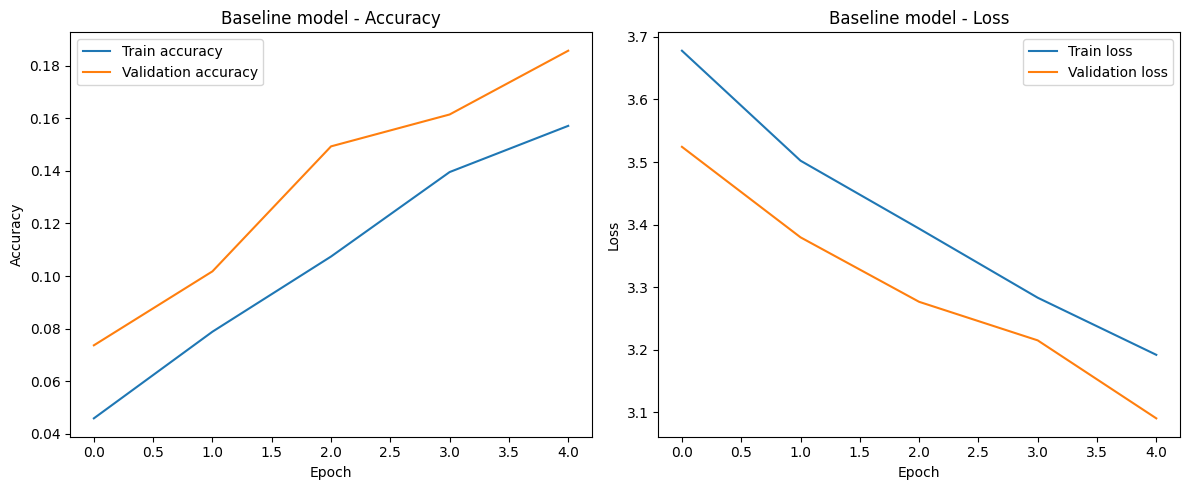

65/65 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - accuracy: 0.1755 - loss: 3.1199
Test loss: 3.1199228763580322
Test accuracy: 0.17547261714935303


In [ ]:
from pathlib import Path
import zipfile
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split

# 1. Povezivanje Google Drive-a
from google.colab import drive
drive.mount("/content/drive")

# 2. Pronalaženje ili raspakivanje dataset-a
DATA_DIR = Path("/content/mammals_dataset")
DATA_ROOT = DATA_DIR / "mammals"

if not DATA_ROOT.exists():
    zip_name = "Mammlas_Image_Classification_Dataset.zip"
    found_files = list(Path("/content/drive/MyDrive").rglob(zip_name))

    if len(found_files) == 0:
        raise FileNotFoundError("ZIP fajl nije pronađen u Google Drive-u.")

    ZIP_PATH = found_files[0]
    print("Pronađen ZIP:", ZIP_PATH)

    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(DATA_DIR)

print("DATA_ROOT:", DATA_ROOT)
print("Dataset postoji:", DATA_ROOT.exists())

# 3. Priprema putanja i labela
class_names = sorted([folder.name for folder in DATA_ROOT.iterdir() if folder.is_dir()])
NUM_CLASSES = len(class_names)

image_paths = []
labels = []

for label, class_name in enumerate(class_names):
    class_folder = DATA_ROOT / class_name

    for image_path in class_folder.iterdir():
        if image_path.suffix.lower() in [".jpg", ".jpeg", ".png"]:
            image_paths.append(str(image_path))
            labels.append(label)

df = pd.DataFrame({
    "image_path": image_paths,
    "label": labels
})

print("Broj klasa:", NUM_CLASSES)
print("Ukupan broj slika:", len(df))

# 4. Train / validation / test podela
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

print("Broj slika za trening:", len(train_df))
print("Broj slika za validaciju:", len(val_df))
print("Broj slika za test:", len(test_df))

# 5. TensorFlow dataset
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

def load_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = image / 255.0
    return image, label

def create_dataset(dataframe, shuffle=False):
    paths = dataframe["image_path"].values
    labels = dataframe["label"].values

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    dataset = dataset.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)

    if shuffle:
        dataset = dataset.shuffle(buffer_size=1000)

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset

train_ds = create_dataset(train_df, shuffle=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

# 6. Baseline CNN model
baseline_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(NUM_CLASSES, activation="softmax")
])

baseline_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 7. Treniranje baseline modela
EPOCHS = 5

history_baseline = baseline_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

# 8. Grafikoni
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_baseline.history["accuracy"], label="Train accuracy")
plt.plot(history_baseline.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Baseline model - Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_baseline.history["loss"], label="Train loss")
plt.plot(history_baseline.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Baseline model - Loss")
plt.legend()

plt.tight_layout()
plt.show()

# 9. Testiranje
test_loss, test_accuracy = baseline_model.evaluate(test_ds)

print("Test loss:", test_loss)
print("Test accuracy:", test_accuracy)

Baseline CNN model je nakon 5 epoha ostvario test tačnost od približno 15.90%. Pošto dataset sadrži 45 klasa, slučajno pogađanje bi iznosilo oko 2.22%, što znači da model uči određene vizuelne obrasce iz slika. Ipak, rezultat nije visok, što je očekivano jer je korišćena jednostavna CNN arhitektura trenirana od početka. Zbog toga će u nastavku biti primenjen transfer learning model, koji koristi prethodno naučene karakteristike iz velikih skupova slika.

## Transfer learning model - MobileNetV2

Za glavni model korišćen je MobileNetV2, konvoluciona neuronska mreža prethodno trenirana na velikom ImageNet skupu podataka. Ovaj pristup se naziva transfer learning, jer model koristi već naučene vizuelne karakteristike kao što su ivice, teksture i oblici, a zatim se prilagođava konkretnom problemu klasifikacije sisara.

In [ ]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras import layers, models
import tensorflow as tf
import matplotlib.pyplot as plt

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

def load_image_mobilenet(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = preprocess_input(image)
    return image, label

def create_mobilenet_dataset(dataframe, shuffle=False):
    paths = dataframe["image_path"].values
    labels = dataframe["label"].values

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    dataset = dataset.map(load_image_mobilenet, num_parallel_calls=tf.data.AUTOTUNE)

    if shuffle:
        dataset = dataset.shuffle(buffer_size=1000)

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset

train_ds_mobilenet = create_mobilenet_dataset(train_df, shuffle=True)
val_ds_mobilenet = create_mobilenet_dataset(val_df)
test_ds_mobilenet = create_mobilenet_dataset(test_df)

base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

mobilenet_model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASSES, activation="softmax")
])

mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

mobilenet_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 45)             │        57,645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,315,629 (8.83 MB)

 Trainable params: 57,645 (225.18 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
EPOCHS = 5

history_mobilenet = mobilenet_model.fit(
    train_ds_mobilenet,
    validation_data=val_ds_mobilenet,
    epochs=EPOCHS
)

Epoch 1/5
301/301 ━━━━━━━━━━━━━━━━━━━━ 38s 87ms/step - accuracy: 0.6763 - loss: 1.3943 - val_accuracy: 0.8822 - val_loss: 0.4947
Epoch 2/5
301/301 ━━━━━━━━━━━━━━━━━━━━ 15s 46ms/step - accuracy: 0.8960 - loss: 0.4186 - val_accuracy: 0.9069 - val_loss: 0.3562
Epoch 3/5
301/301 ━━━━━━━━━━━━━━━━━━━━ 14s 45ms/step - accuracy: 0.9212 - loss: 0.2946 - val_accuracy: 0.9132 - val_loss: 0.3072
Epoch 4/5
301/301 ━━━━━━━━━━━━━━━━━━━━ 15s 47ms/step - accuracy: 0.9387 - loss: 0.2340 - val_accuracy: 0.9176 - val_loss: 0.2846
Epoch 5/5
301/301 ━━━━━━━━━━━━━━━━━━━━ 15s 45ms/step - accuracy: 0.9496 - loss: 0.1905 - val_accuracy: 0.9152 - val_loss: 0.2733


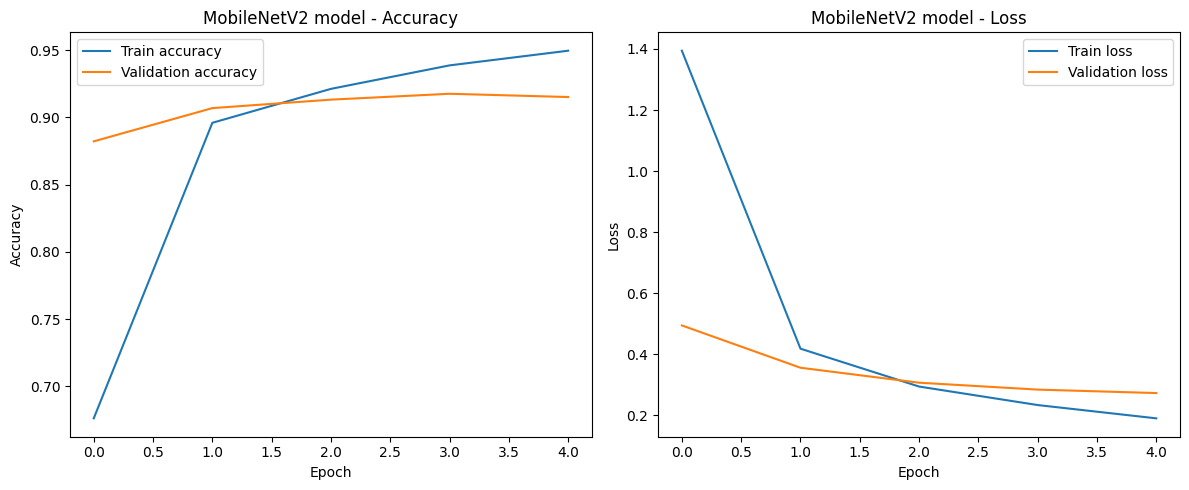

65/65 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - accuracy: 0.9244 - loss: 0.2619
MobileNetV2 test loss: 0.26189565658569336
MobileNetV2 test accuracy: 0.9243819713592529


In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_mobilenet.history["accuracy"], label="Train accuracy")
plt.plot(history_mobilenet.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("MobileNetV2 model - Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_mobilenet.history["loss"], label="Train loss")
plt.plot(history_mobilenet.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MobileNetV2 model - Loss")
plt.legend()

plt.tight_layout()
plt.show()

test_loss_mobilenet, test_accuracy_mobilenet = mobilenet_model.evaluate(test_ds_mobilenet)

print("MobileNetV2 test loss:", test_loss_mobilenet)
print("MobileNetV2 test accuracy:", test_accuracy_mobilenet)

MobileNetV2 model je postigao znatno bolje rezultate od baseline CNN modela. Validaciona tačnost nakon 5 epoha iznosila je približno 92.05%, dok je trening tačnost iznosila približno 94.95%. Ovo pokazuje da transfer learning značajno poboljšava performanse, jer model koristi prethodno naučene vizuelne karakteristike iz velikog ImageNet skupa podataka.

Razlika između trening i validacione tačnosti nije velika, što znači da model ne pokazuje izraženo preprilagođavanje na trening skup. Validacioni loss se tokom epoha smanjuje, što ukazuje na stabilno učenje modela.

## Poređenje baseline i MobileNetV2 modela

U ovom delu upoređeni su rezultati jednostavnog baseline CNN modela i MobileNetV2 modela zasnovanog na transfer learning-u.

In [ ]:
comparison_df = pd.DataFrame({
    "Model": ["Baseline CNN", "MobileNetV2"],
    "Test accuracy": [test_accuracy, test_accuracy_mobilenet],
    "Test loss": [test_loss, test_loss_mobilenet]
})

comparison_df

,Model,Test accuracy,Test loss
0,Baseline CNN,0.175473,3.119923
1,MobileNetV2,0.924382,0.261896


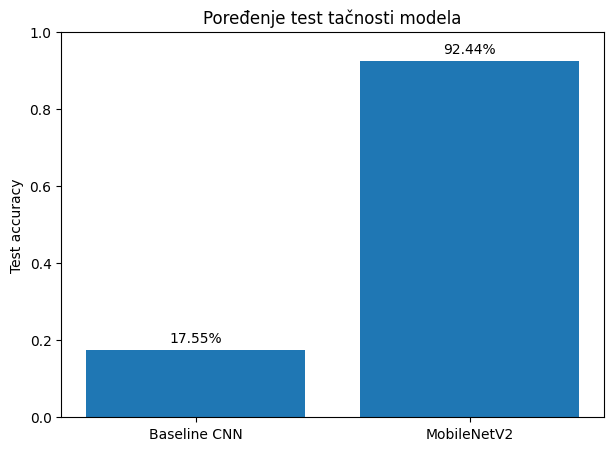

In [ ]:
plt.figure(figsize=(7, 5))
plt.bar(comparison_df["Model"], comparison_df["Test accuracy"])
plt.ylabel("Test accuracy")
plt.title("Poređenje test tačnosti modela")
plt.ylim(0, 1)

for i, value in enumerate(comparison_df["Test accuracy"]):
    plt.text(i, value + 0.02, f"{value:.2%}", ha="center")

plt.show()

Baseline CNN model ostvario je test tačnost od približno 15.90%, dok je MobileNetV2 model ostvario test tačnost od približno 92.58%. Ova razlika pokazuje da transfer learning ima značajnu prednost kod klasifikacije slika, naročito kada se koristi model prethodno treniran na velikom skupu podataka kao što je ImageNet. MobileNetV2 koristi već naučene karakteristike slika, dok baseline model sve karakteristike uči od početka, zbog čega postiže znatno slabiji rezultat.

## Matrica konfuzije i analiza grešaka

Nakon poređenja modela, analizirana je matrica konfuzije za MobileNetV2 model. Matrica konfuzije prikazuje koliko je slika iz svake stvarne klase klasifikovano u odgovarajuću ili pogrešnu klasu. Na ovaj način može se videti koje klase model dobro prepoznaje, a kod kojih dolazi do grešaka.

Classification report:
                  precision    recall  f1-score   support

african_elephant      0.981     1.000     0.990        52
          alpaca      0.807     0.920     0.860        50
  american_bison      0.959     0.922     0.940        51
        anteater      0.780     0.867     0.821        45
      arctic_fox      0.885     0.979     0.929        47
       armadillo      0.980     0.980     0.980        50
          baboon      0.942     1.000     0.970        49
          badger      0.977     0.913     0.944        46
      blue_whale      0.861     0.861     0.861        36
      brown_bear      0.977     0.933     0.955        45
           camel      0.939     0.816     0.873        38
         dolphin      0.935     0.915     0.925        47
         giraffe      1.000     0.935     0.966        46
       groundhog      0.957     0.978     0.968        46
 highland_cattle      0.957     0.936     0.946        47
           horse      0.935     0.935     0.935 

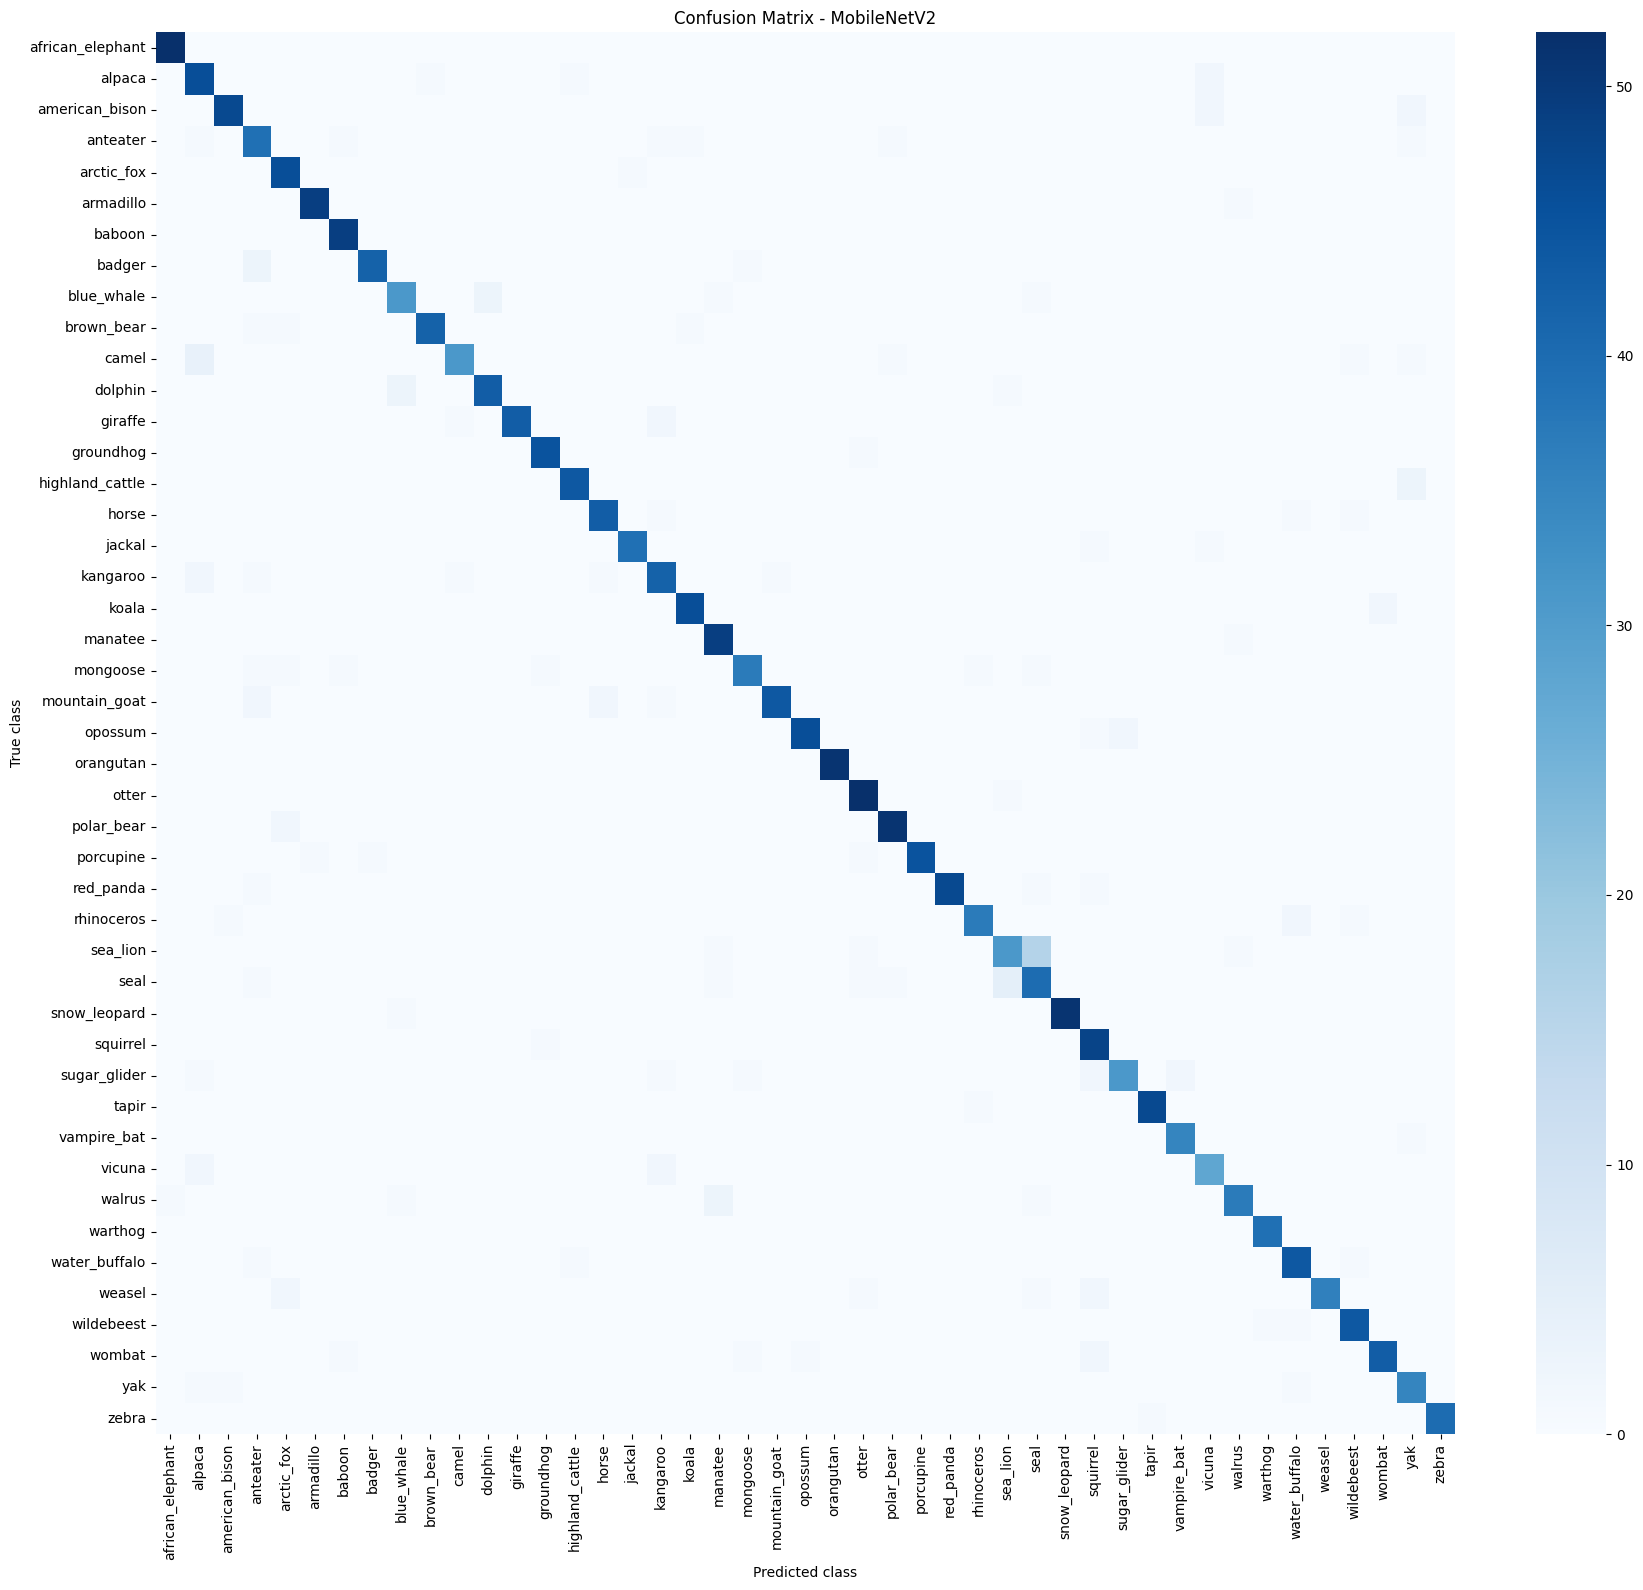

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

y_true = []
y_pred = []

for images, labels in test_ds_mobilenet:
    predictions = mobilenet_model.predict(images, verbose=0)
    predicted_labels = np.argmax(predictions, axis=1)

    y_true.extend(labels.numpy())
    y_pred.extend(predicted_labels)

print("Classification report:")
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(18, 16))
sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("Confusion Matrix - MobileNetV2")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Najčešće greške modela

Pošto dataset sadrži veliki broj klasa, dodatno su izdvojene najčešće greške MobileNetV2 modela. Na ovaj način se jasnije vidi koje vrste sisara model najčešće meša.

In [ ]:
import pandas as pd

errors = []

for true_label, pred_label in zip(y_true, y_pred):
    if true_label != pred_label:
        errors.append({
            "true_class": class_names[true_label],
            "predicted_class": class_names[pred_label]
        })

errors_df = pd.DataFrame(errors)

print("Ukupan broj grešaka:", len(errors_df))
print("Ukupan broj test slika:", len(y_true))
print("Tačnost iz grešaka:", 1 - len(errors_df) / len(y_true))

top_errors = (
    errors_df
    .value_counts(["true_class", "predicted_class"])
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)

top_errors.head(15)

Ukupan broj grešaka: 156
Ukupan broj test slika: 2063
Tačnost iz grešaka: 0.9243819680077557


,true_class,predicted_class,count
0,sea_lion,seal,16
1,seal,sea_lion,5
2,camel,alpaca,4
3,dolphin,blue_whale,3
4,blue_whale,dolphin,3
5,badger,anteater,3
6,highland_cattle,yak,3
7,walrus,manatee,3
8,american_bison,yak,2
9,kangaroo,alpaca,2


Na test skupu MobileNetV2 model je napravio 156 grešaka od ukupno 2063 test slike, što odgovara tačnosti od približno 92.44%. Najčešća greška je bila zamena klase `sea_lion` sa klasom `seal`, ukupno 16 puta. Ovo je očekivano jer su ove dve klase vizuelno veoma slične: obe predstavljaju morske sisare sličnog oblika tela, boje i okruženja u kojem se najčešće nalaze.

Model je takođe nekoliko puta pomešao klase `seal` i `sea_lion`, kao i `dolphin` i `blue_whale`, što takođe ima smisla jer se radi o životinjama sličnog staništa i vizuelnih karakteristika. Greške kao što su `camel` prepoznat kao `alpaca`, `highland_cattle` kao `yak`, ili `vicuna` kao `alpaca` ukazuju na to da model najčešće greši kod životinja koje imaju sličan oblik tela, krzno ili položaj u slici.

Na osnovu ovih rezultata može se zaključiti da MobileNetV2 model veoma dobro klasifikuje većinu slika, ali da su najveći izazov vizuelno slične klase. Dodatno unapređenje moglo bi se postići korišćenjem većeg broja slika za problematične klase, dodatnom augmentacijom podataka ili finim podešavanjem prethodno treniranog modela.

## Primeri pogrešno klasifikovanih slika

U nastavku su prikazani primeri slika koje je MobileNetV2 model pogrešno klasifikovao. Iznad svake slike prikazana je stvarna klasa i klasa koju je model predvideo.

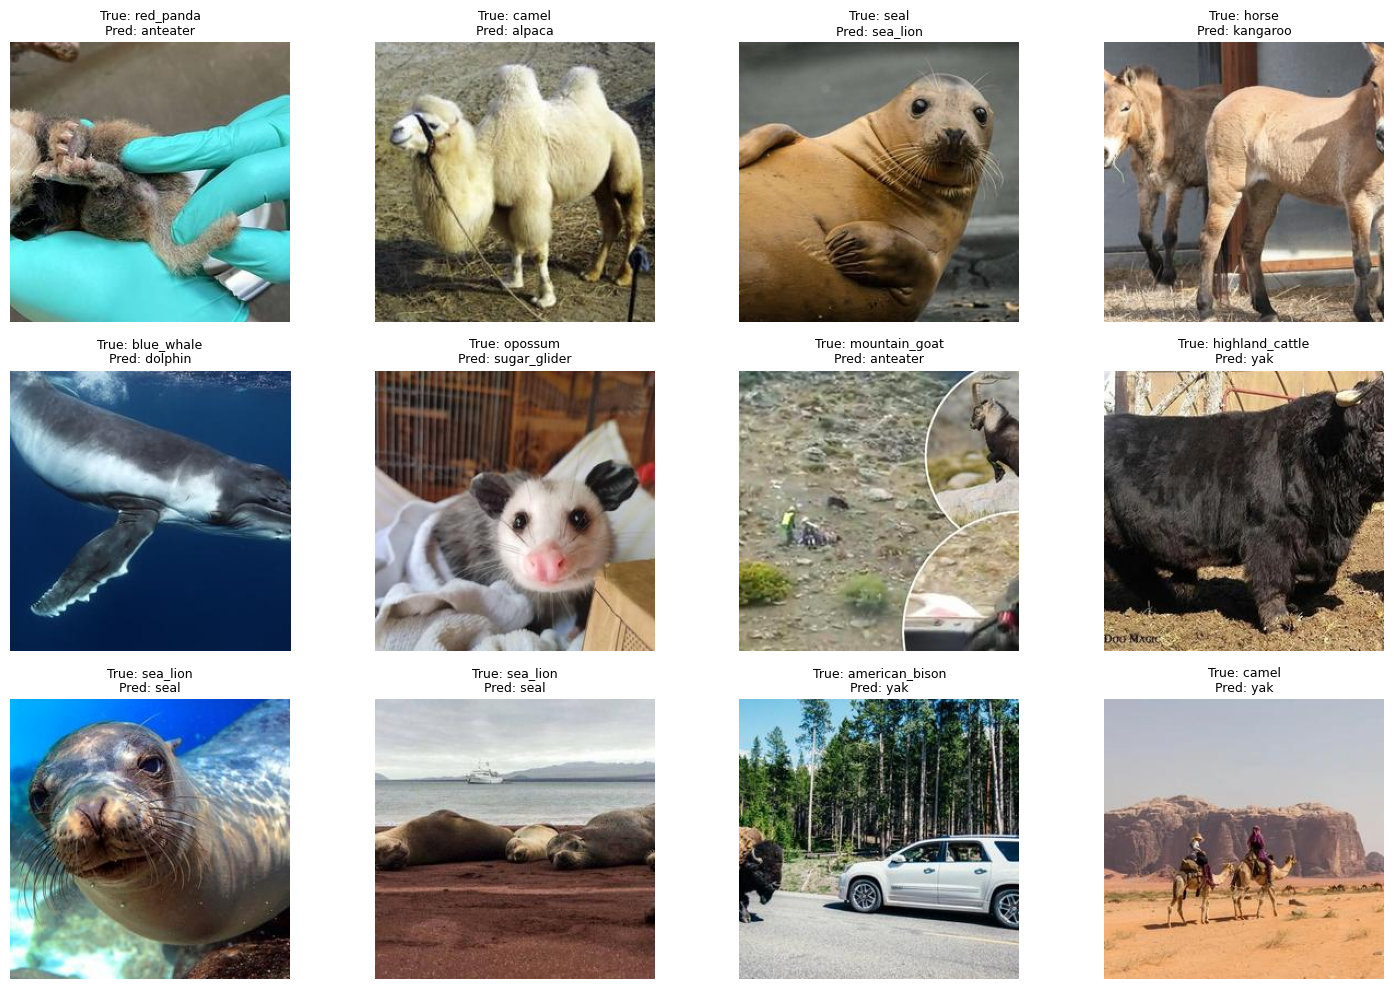

In [ ]:
misclassified_examples = []

for image_path, true_label, pred_label in zip(test_df["image_path"], y_true, y_pred):
    if true_label != pred_label:
        misclassified_examples.append({
            "image_path": image_path,
            "true_class": class_names[true_label],
            "predicted_class": class_names[pred_label]
        })

misclassified_df = pd.DataFrame(misclassified_examples)

plt.figure(figsize=(15, 10))

for i, row in misclassified_df.head(12).iterrows():
    image = Image.open(row["image_path"]).convert("RGB")

    plt.subplot(3, 4, i + 1)
    plt.imshow(image)
    plt.title(
        f"True: {row['true_class']}\nPred: {row['predicted_class']}",
        fontsize=9
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

## Zaključak

U ovom projektu obrađen je problem klasifikacije slika sisara u 45 različitih klasa. Dataset je sadržao ukupno 13.751 sliku, pri čemu su slike bile organizovane po folderima koji predstavljaju klase. Pre treniranja modela izvršena je analiza skupa podataka, prikazana je raspodela broja slika po klasama, analizirane su dimenzije slika i prikazani su primeri slika iz različitih klasa.

Podaci su podeljeni na trening, validacioni i test skup u odnosu 70:15:15. Trening skup je sadržao 9625 slika, validacioni 2063 slike, a test skup 2063 slike. Slike su pre treniranja resize-ovane na dimenziju 224x224 piksela i pripremljene za rad sa TensorFlow modelima.

Kao početni model korišćena je jednostavna konvoluciona neuronska mreža. Baseline CNN model ostvario je test tačnost od približno 15.90%. Ovaj rezultat je bolji od slučajnog pogađanja, ali pokazuje da jednostavna arhitektura nije dovoljna za složen problem klasifikacije 45 različitih vrsta sisara.

Kao napredniji model korišćen je MobileNetV2 zasnovan na transfer learning-u. MobileNetV2 model ostvario je test tačnost od približno 92.58%, što predstavlja značajno poboljšanje u odnosu na baseline model. Ovaj rezultat pokazuje da korišćenje prethodno treniranih modela može znatno poboljšati performanse kod klasifikacije slika.

Analizom grešaka utvrđeno je da model najčešće greši kod vizuelno sličnih klasa, kao što su `sea_lion` i `seal`, `dolphin` i `blue_whale`, kao i `alpaca`, `vicuna` i `camel`. Ove greške su očekivane jer navedene klase imaju sličan oblik tela, boju, teksturu ili okruženje u kojem se nalaze.

Na osnovu dobijenih rezultata može se zaključiti da je MobileNetV2 pogodan model za ovaj zadatak. Moguća dalja unapređenja uključuju dodatnu augmentaciju podataka, fino podešavanje prethodno treniranog modela, veći broj epoha uz praćenje overfitting-a, kao i korišćenje drugih arhitektura kao što su EfficientNet ili ResNet.